In [63]:
import pandas as pd
import numpy as np
from google.colab import files
import io
import joblib
import os
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_selection import  SelectKBest,mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from functools import partial
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC
from functools import partial
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
from IPython.display import display as show_table



In [2]:
print(os.listdir('/content'))

['.config', '.ipynb_checkpoints', 'Telco_Customer_Churn_Dataset  .csv', 'sample_data']


In [6]:
print(os.listdir('/content'))

['.config', '.ipynb_checkpoints', 'Telco_Customer_Churn_Dataset.csv', 'sample_data']


In [7]:
df=pd.read_csv('Telco_Customer_Churn_Dataset.csv')

In [8]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [9]:
print(df.shape[0])
print(df.shape[1])
df.info()
print(df.isnull().sum())
print(df.duplicated().sum())
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True)*100)

7043
21
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   

In [10]:
for column in df.select_dtypes(include="object").columns:
  empty_count=df[column].astype(str).str.strip().eq('').sum()
  if empty_count>0:
    print(f"{column}:{empty_count} empty values")

TotalCharges:11 empty values


In [11]:
df_clean=df.copy()
for column in df_clean.select_dtypes(include="object").columns:
  df_clean[column]=df_clean[column].str.strip()
df_clean['TotalCharges']=pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)
print("totalCharges data type:",df_clean["TotalCharges"].dtype)
print("missing totalCharges:",df_clean["TotalCharges"].isnull().sum())



totalCharges data type: float64
missing totalCharges: 11


In [12]:
missing_rows=df_clean[df_clean["TotalCharges"].isnull()]
missing_rows[['customerID','tenure','MonthlyCharges','TotalCharges','Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [13]:
df_clean["TotalCharges"]=df_clean['TotalCharges'].fillna(0.0)
print(df_clean["TotalCharges"].isnull().sum())
print(df_clean["TotalCharges"].dtype)

0
float64


In [14]:
print(df_clean["TotalCharges"].value_counts(dropna=False))
print(df_clean["Churn"].isnull().sum())

TotalCharges
0.00       11
20.20      11
19.75       9
20.05       8
19.90       8
           ..
130.15      1
3211.90     1
7843.55     1
2196.30     1
197.40      1
Name: count, Length: 6531, dtype: int64
0


In [16]:
df_model=df_clean.drop(columns=["customerID"])
print(df_clean.shape)
print(df_model.shape)

(7043, 21)
(7043, 20)


In [17]:
categorical_columns=df_model.select_dtypes(
    include=["object"]
).columns.tolist()
numerical_columns=df_model.select_dtypes(
    include=['int64','float64']
).columns.tolist()
print("categorical columns:",categorical_columns)
print("number of categorcal columns:",len(categorical_columns))
print("number of numerical columns:",numerical_columns)
print("number of numerical columns:",len(numerical_columns))

categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']
number of categorcal columns: 16
number of numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
number of numerical columns: 4


In [18]:
x=df_model.drop(columns=["Churn"])
y=df_model["Churn"]
print("feature shape:",x.shape)
print("target shape:",y.shape)
print(y.value_counts())


feature shape: (7043, 19)
target shape: (7043,)
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [19]:
categorical_features=x.select_dtypes(
    include=['object']
).columns.tolist()
x_encoded=pd.get_dummies(
    x,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)
y_encoded=y.map({
    "No":0,
    "Yes":1
})


In [20]:
x_encoded.head()


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


In [21]:
print(x_encoded.dtypes.value_counts())
print(x_encoded.select_dtypes(include=['object']).columns.tolist())
print(x_encoded.isnull().sum().sum())
print(y_encoded.isnull().sum())

int64      28
float64     2
Name: count, dtype: int64
[]
0
0


In [22]:
print(df.shape)
print(df_clean.shape)
print(x_encoded.shape)
print(y_encoded.shape)
print(y_encoded.value_counts())

(7043, 21)
(7043, 21)
(7043, 30)
(7043,)
Churn
0    5174
1    1869
Name: count, dtype: int64


In [23]:
x_train,x_test,y_train,y_test=train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y

)

In [24]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)
len(x_train)+len(x_test)

(5634, 19)
(1409, 19)
(5634,)
(1409,)


7043

In [25]:
print(y_train.value_counts())
print(y_train.value_counts(normalize=True)*100)
print(y_test.value_counts())
print(y_test.value_counts(normalize=True)*100)

Churn
No     4139
Yes    1495
Name: count, dtype: int64
Churn
No     73.464679
Yes    26.535321
Name: proportion, dtype: float64
Churn
No     1035
Yes     374
Name: count, dtype: int64
Churn
No     73.456352
Yes    26.543648
Name: proportion, dtype: float64


In [26]:
x_train.to_csv('/content/x_train.csv',index=False)
x_test.to_csv('/content/x_test.csv',index=False)
y_train.to_csv('/content/y_train.csv',index=False)
y_test.to_csv('/content/y_test.csv',index=False)


In [27]:
print(os.getcwd())
print(os.listdir('/content'))

/content
['.config', '.ipynb_checkpoints', 'x_train.csv', 'x_test.csv', 'y_train.csv', 'y_test.csv', 'Telco_Customer_Churn_Dataset.csv', 'sample_data']


In [28]:
categorical_features=[
    col for col in categorical_features
    if col !="Churn"
]
print(categorical_features)
print(len(categorical_features))
print(numerical_columns)
print(len(numerical_columns))
print(len(categorical_features)+len(numerical_columns))

['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
15
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
4
19


In [29]:
y_train_encoded=y_train.map({
    "No":0,
    "Yes":1
})


In [30]:
preprocessor=ColumnTransformer(
    transformers=[
        ('categorical',
         OneHotEncoder(handle_unknown='ignore'),
         categorical_features),
        ('numerical','passthrough',numerical_columns)
    ]
)
x_train_encoded=preprocessor.fit_transform(x_train)
print(x_train.shape)
print(x_train_encoded.shape)

(5634, 19)
(5634, 45)


In [31]:
mi_scores=mutual_info_classif(
    x_train_encoded,
    y_train_encoded,
    random_state=42
)
feature_names=preprocessor.get_feature_names_out()
mi_results=pd.DataFrame({
    'Feature':feature_names,
    'MI_Score':mi_scores
})
mi_results=mi_results.sort_values(
    by='MI_Score',
    ascending=False
).reset_index(drop=True)
print(mi_results.to_string(index=False))



                                             Feature  MI_Score
                categorical__Contract_Month-to-month  0.099410
                                   numerical__tenure  0.068552
                         categorical__TechSupport_No  0.066619
                      categorical__OnlineSecurity_No  0.059462
                      categorical__Contract_Two year  0.056251
                           numerical__MonthlyCharges  0.050003
            categorical__InternetService_Fiber optic  0.048373
                             numerical__TotalCharges  0.038010
         categorical__PaymentMethod_Electronic check  0.037794
                        categorical__OnlineBackup_No  0.036993
                     categorical__InternetService_No  0.032893
     categorical__OnlineSecurity_No internet service  0.032542
        categorical__StreamingTV_No internet service  0.031208
    categorical__StreamingMovies_No internet service  0.029473
                    categorical__DeviceProtection_No  0

In [32]:
cv=StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
k_values=[10,15,20,25,30,45]
results=[]
for k in k_values:
  pipeline=Pipeline([
      ('preprocessing',preprocessor),
      ('feature_selection',SelectKBest(
          score_func=partial(
              mutual_info_classif,
              random_state=42
          ),
          k=k
      )),
     ('model',LogisticRegression(max_iter=3000,solver='lbfgs'))
  ])
  scores=cross_val_score(
      pipeline,
      x_train,
      y_train_encoded,
      cv=cv,
      scoring="roc_auc"
  )
  results.append({
      "number_of_features":k,
      "mean_roc_auc":scores.mean(),
      "standard_deviation":scores.std()
  })
  results_df=pd.DataFrame(results)
  print(results_df.to_string(index=False))


 number_of_features  mean_roc_auc  standard_deviation
                 10      0.841325             0.01283
 number_of_features  mean_roc_auc  standard_deviation
                 10      0.841325            0.012830
                 15      0.842187            0.013195


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

 number_of_features  mean_roc_auc  standard_deviation
                 10      0.841325            0.012830
                 15      0.842187            0.013195
                 20      0.844431            0.012647


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


 number_of_features  mean_roc_auc  standard_deviation
                 10      0.841325            0.012830
                 15      0.842187            0.013195
                 20      0.844431            0.012647
                 25      0.844290            0.011727


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


 number_of_features  mean_roc_auc  standard_deviation
                 10      0.841325            0.012830
                 15      0.842187            0.013195
                 20      0.844431            0.012647
                 25      0.844290            0.011727
                 30      0.845611            0.011910
 number_of_features  mean_roc_auc  standard_deviation
                 10      0.841325            0.012830
                 15      0.842187            0.013195
                 20      0.844431            0.012647
                 25      0.844290            0.011727
                 30      0.845611            0.011910
                 45      0.846310            0.012689


In [33]:
selection_pipeline=Pipeline([
    ('preprocessing',preprocessor),
    ('feature_selection',SelectKBest(
        score_func=partial(
            mutual_info_classif,
            random_state=42

        ),
        k=30
    ))
])
selection_pipeline.fit(x_train,y_train_encoded)
all_feature_names=(
    selection_pipeline
    .named_steps['preprocessing']
    .get_feature_names_out()
)
selected_mask=(
    selection_pipeline
    .named_steps['feature_selection']
    .get_support()
)
selected_features=all_feature_names[selected_mask]
for i, feature in enumerate(selected_features,start=1):
  print(f"{i}.{feature}")
print(len(selected_features))

1.categorical__gender_Female
2.categorical__Partner_No
3.categorical__Dependents_Yes
4.categorical__InternetService_Fiber optic
5.categorical__InternetService_No
6.categorical__OnlineSecurity_No
7.categorical__OnlineSecurity_No internet service
8.categorical__OnlineSecurity_Yes
9.categorical__OnlineBackup_No
10.categorical__OnlineBackup_No internet service
11.categorical__DeviceProtection_No
12.categorical__DeviceProtection_No internet service
13.categorical__TechSupport_No
14.categorical__TechSupport_No internet service
15.categorical__TechSupport_Yes
16.categorical__StreamingTV_No internet service
17.categorical__StreamingTV_Yes
18.categorical__StreamingMovies_No
19.categorical__StreamingMovies_No internet service
20.categorical__Contract_Month-to-month
21.categorical__Contract_One year
22.categorical__Contract_Two year
23.categorical__PaperlessBilling_No
24.categorical__PaperlessBilling_Yes
25.categorical__PaymentMethod_Bank transfer (automatic)
26.categorical__PaymentMethod_Electro

In [34]:
x_train_selected=selection_pipeline.transform(x_train)
x_test_selected=selection_pipeline.transform(x_test)
print(x_train_selected.shape)
print(x_test_selected.shape)

(5634, 30)
(1409, 30)


In [35]:
x_train_selected=pd.DataFrame(
    x_train_seleccted.toarray()
    if hasattr(x_train_selected,"toarray")
    else x_train_selected,
    columns=selected_features
)
x_test_selected=pd.DataFrame(
    x_test_selected.toarray()
    if hasattr(x_test_selected,"toarray")
    else x_test_selected,
    columns=selected_features
)
x_train_selected.to_csv(
    '/content/x_train_selected.csv',index=False
)
x_test_selected.to_csv(
    '/content/x_test_selected.csv',index=False
)

In [36]:
models={
    'Logistic Regression':LogisticRegression(max_iter=3000),
    'DecisionTree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    'Gradient Boosting':GradientBoostingClassifier(
        random_state=42
    ),
    'k-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5)

}
for name in models:
  print(name)

Logistic Regression
DecisionTree
Random Forest
Gradient Boosting
k-Nearest Neighbors


In [40]:
model_results=[]
for name,model in models.items():
  pipeline=Pipeline([
      ('preprocessing',preprocessor),
      ('feature_selection',SelectKBest(
          score_func=partial(mutual_info_classif,random_state=42),
          k=30
      )),
      ('scaling',StandardScaler(with_mean=False)),
      ('model',model)
  ])
  scores=cross_val_score(
      pipeline,
      x_train,
      y_train_encoded,
      cv=cv,
      scoring="roc_auc",
      n_jobs=-1
  )
  model_results.append({
      'Model':name,
      'Mean ROC-AUC':scores.mean(),
      'Standard Deviation':scores.std()
  })
  results_df=pd.DataFrame(model_results)
  results_df=results_df.sort_values(
      by='Mean ROC-AUC',
      ascending=False
  ).reset_index(drop=True)
  print(results_df.to_string(index=False))


              Model  Mean ROC-AUC  Standard Deviation
Logistic Regression      0.845614            0.011783
              Model  Mean ROC-AUC  Standard Deviation
Logistic Regression      0.845614            0.011783
       DecisionTree      0.664930            0.009299
              Model  Mean ROC-AUC  Standard Deviation
Logistic Regression      0.845614            0.011783
      Random Forest      0.818576            0.012857
       DecisionTree      0.664930            0.009299
              Model  Mean ROC-AUC  Standard Deviation
  Gradient Boosting      0.846644            0.012677
Logistic Regression      0.845614            0.011783
      Random Forest      0.818576            0.012857
       DecisionTree      0.664930            0.009299
              Model  Mean ROC-AUC  Standard Deviation
  Gradient Boosting      0.846644            0.012677
Logistic Regression      0.845614            0.011783
      Random Forest      0.818576            0.012857
k-Nearest Neighbors      0.7

In [41]:
results_df.to_csv(
    '/content/model_selection_results.csv',
    index=False
)

In [43]:
final_model=Pipeline([
    ('preprocessing',preprocessor),
    ('feature_selection',SelectKBest(
        score_func=partial(mutual_info_classif,random_state=42),
        k=30
    )),
    ('model',GradientBoostingClassifier(
         n_estimators=100,
         learning_rate=0.1,
         max_depth=3,
         random_state=42

    ))
])
final_model.fit(x_train,y_train_encoded)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod']),
                                                 ('numerical', 'passthrough',
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges'])])),
                ('feature_selection',
                 SelectKBest(k=30,
                             score_func=functools.partial(<function mutual_info_classif at 0x7959d2e187c0>, random_state=42))),
                ('model', GradientBoostingClassifier(random_state=42))])

In [44]:
print("model fitted:",final_model.__sklearn_is_fitted__())

model fitted: True


In [46]:
joblib.dump(
    final_model,
    '/content/customer_churn_model.joblib'
)

['/content/customer_churn_model.joblib']

In [47]:
y_pred=final_model.predict(x_test)
y_pred_proba=final_model.predict_proba(x_test)[:,1]
print(len(y_pred))
print(len(y_pred_proba))
print(y_pred[:10])

1409
1409
[0 1 0 0 0 1 1 0 0 0]


In [51]:
y_test_encoded=y_test.map({'No':0,'Yes':1})

In [54]:
accuracy=accuracy_score(y_test_encoded,y_pred)
precision=precision_score(y_test_encoded,y_pred)
recall=recall_score(y_test_encoded,y_pred)
f1=f1_score(y_test_encoded,y_pred)
roc_auc=roc_auc_score(y_test_encoded,y_pred_proba)
print(f"Accuracy:{accuracy:.4f}")
print(f"Precision:{precision:.4f}")
print(f"recall:{recall:.4f}")
print(f"F1-Score:{f1:.4f}")
print(f"roc-auc:{roc_auc:.4f}")

Accuracy:0.8027
Precision:0.6579
recall:0.5348
F1-Score:0.5900
roc-auc:0.8419


In [53]:
print(y_test_encoded.value_counts())
print(y_test_encoded.isnull().sum())

Churn
0    1035
1     374
Name: count, dtype: int64
0


[[931 104]
 [174 200]]


<function matplotlib.pyplot.show(close=None, block=None)>

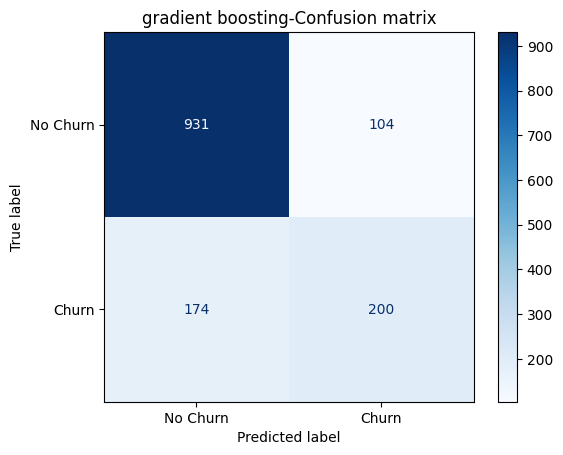

In [57]:
cm=confusion_matrix(y_test_encoded,y_pred)
print(cm)
display=ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Churn','Churn']

)
display.plot(cmap='Blues',values_format='d')
plt.title("gradient boosting-Confusion matrix")
plt.show

In [64]:
report=classification_report(
    y_test_encoded,
    y_pred,
    target_names=['No Churn','Churn'],
    output_dict=True
)
report_df=pd.DataFrame(report).transpose()
show_table(report_df)

report_df.to_csv('/content/classification_report.csv')


,precision,recall,f1-score,support
No Churn,0.842534,0.899517,0.870093,1035.000000
Churn,0.657895,0.534759,0.589971,374.000000
accuracy,0.802697,0.802697,0.802697,0.802697
macro avg,0.750214,0.717138,0.730032,1409.000000
weighted avg,0.793524,0.802697,0.795739,1409.000000


In [67]:
evaluation_results=pd.DataFrame([{
    'model':'Gradient Boosting',
    'Accuracy':accuracy_score(y_test_encoded,y_pred),
    'Precision':precision_score(y_test_encoded,y_pred),
    'Recall':recall_score(y_test_encoded,y_pred),
    'ROC-AUC':roc_auc_score(y_test_encoded,y_pred_proba)
}])
evaluation_results.to_csv(
    '/content/model_evaluation_results.csv',
    index=False
)
cm=confusion_matrix(y_test_encoded,y_pred)
cm_df=pd.DataFrame(
    cm,
    index=['actual no churn','actual churn'],
    columns=['predicted no churn','predicted churn']
)
cm_df.to_csv('/content/confusion_matrix.csv')
show_table(evaluation_results)
show_table(cm_df)


,model,Accuracy,Precision,Recall,ROC-AUC
0,Gradient Boosting,0.802697,0.657895,0.534759,0.841879


,predicted no churn,predicted churn
actual no churn,931,104
actual churn,174,200
